Побудувати «найкращу» модель методом усiх регресiй.
Перевiрити, чи добре специфiкована обрана модель за критерiєм Рамсея.
Оцiнити специфiкацiю «найкращих» моделей кожної групи за критерiєм Амемiї.

In [8]:
import pandas as pd
import numpy as np
from scipy import stats
from itertools import combinations
import matplotlib.pyplot as plt
import statsmodels.api as sm

data = {
    'Країна': [
        'Австралія', 'Австрія', 'Аргентина', 'Бангладеш', 'Бельгія', 'Білорусь', 'Бразилія', 'Буркіна-Фасо', 
        'Велика Британія', "В'єтнам", 'Гаїті', 'Гондурас', 'Гонконг', 'Ефіопія', 'Єгипет', 'Замбія', 'Індія', 
        'Ірландія', 'Іспанія', 'Італія', 'Канада', 'Китай', 'Колумбія', 'Коста-Рика', 'Куба', 'Малайзія', 
        'Марокко', 'Мексика', 'Нідерланди', 'Німеччина', 'Нова Зеландія', 'Норвегія', 'ОАЕ', 'ПАР', 
        'Південна Корея', 'Північна Корея', 'Польща', 'Португалія', 'Росія', 'Саудівська Аравія', 'Сінгапур', 
        'США', 'Таїланд', 'Туреччина', 'Україна', 'Філіппіни', 'Фінляндія', 'Франція', 'Чилі', 'Швейцарія', 
        'Швеція', 'Японія'
    ],
    'X0': np.ones(52),
    'Y1': [74, 73, 68, 53, 73, 66, 57, 47, 74, 63, 43, 65, 75, 51, 60, 44, 58, 73, 74, 74, 74, 67, 69, 76, 74, 66, 66, 69, 75, 73, 73, 74, 70, 62, 68, 67, 69, 71, 64, 66, 73, 73, 65, 69, 65, 63, 72, 74, 71, 75, 75, 76],
    'X1': [17800, 8000, 33900, 125000, 10100, 10300, 156600, 10000, 58400, 73100, 6500, 5600, 5800, 55200, 60000, 9100, 911600, 3600, 39200, 58100, 29100, 1205200, 35600, 3300, 11100, 19500, 28600, 91800, 15400, 81200, 3524, 4300, 2800, 43900, 45000, 23100, 38600, 10500, 149200, 18000, 2900, 260800, 59400, 62200, 51800, 69800, 5100, 58000, 14000, 7000, 8800, 125500],
    'X2': [15, 12, 20, 35, 12, 13, 21, 47, 13, 27, 40, 35, 13, 45, 29, 46, 29, 14, 11, 11, 14, 21, 24, 26, 17, 29, 29, 28, 13, 11, 16, 13, 28, 34, 16, 24, 14, 12, 13, 38, 16, 15, 19, 26, 12, 27, 13, 13, 23, 12, 14, 11],
    'X3': [8, 11, 9, 11, 11, 11, 9, 18, 11, 8, 19, 6, 6, 14, 9, 18, 10, 9, 9, 10, 8, 7, 6, 4, 7, 5, 6, 5, 9, 11, 8, 10, 3, 8, 6, 6, 10, 10, 11, 6, 6, 9, 6, 6, 13, 7, 10, 9, 6, 9, 11, 7],
    'X4': [16848, 18396, 3408, 202, 17912, 6500, 2354, 357, 15974, 230, 383, 1030, 14641, 122, 748, 573, 275, 12170, 13047, 17500, 19904, 377, 1538, 2031, 1382, 2995, 1062, 3604, 17245, 17539, 14381, 17755, 14193, 3128, 6627, 1000, 4429, 9000, 6680, 6651, 14990, 23474, 1800, 3721, 2340, 867, 15877, 18944, 2591, 22384, 16900, 19860],
    'X5': [85, 58, 86, 16, 96, 65, 75, 15, 89, 20, 29, 44, 94, 12, 44, 42, 26, 57, 78, 69, 77, 26, 70, 47, 74, 43, 46, 73, 89, 85, 84, 75, 81, 49, 72, 60, 62, 34, 74, 77, 100, 75, 22, 61, 67, 43, 60, 73, 85, 62, 84, 77]
}
df = pd.DataFrame(data)

In [2]:
def all_subsets_regression(df, target_col='Y1', constant_col='X0'):
    y = df[target_col].to_numpy()
    T = len(y)
    
    regressors = [col for col in df.columns if col not in ['Країна', target_col, constant_col]]
    
    # Крок 1. Повнофакторна модель для розрахунку sigma2_full (для Cp-статистики)
    X_full_cols = [constant_col] + regressors
    X_full = df[X_full_cols].to_numpy()
    N_full = X_full.shape[1]
    
    beta_full = np.linalg.inv(X_full.T @ X_full) @ X_full.T @ y
    u_full = y - (X_full @ beta_full)
    RSS_full = u_full.T @ u_full
    sigma2_full = RSS_full / (T - N_full)
    
    TSS = np.sum((y - np.mean(y))**2)
    
    results = []
    
    # Словник для визначення назв груп (А - 1 регресор, Б - 2, В - 3, Г - 4, Д - 5, Е - 6)
    group_names = {0: 'А', 1: 'Б', 2: 'В', 3: 'Г', 4: 'Д', 5: 'Е'}

    # Крок 2. Перебір комбінацій регресорів
    for k in range(1, len(regressors) + 1):
        for combo in combinations(regressors, k):
            model_cols = [constant_col] + list(combo)
            X = df[model_cols].to_numpy()
            N = X.shape[1] 
            
            # OLS оцінка (1МНК)
            beta = np.linalg.inv(X.T @ X) @ X.T @ y
            u = y - (X @ beta) # y - y з кришечкою
            RSS = u.T @ u
            
            # Статистики
            r2_adj = 1 - (RSS / (T - N)) / (TSS / (T - 1)) # за Тейлом
            sigma2_u = RSS / (T - N)
            cp_stat = (RSS / sigma2_full) - T + 2 * N # критерій Маллоуза
            
            combo_idx = "".join([col.replace('x', '') for col in combo])
            model_name = "X0" + combo_idx
            
            results.append({
                'Група': group_names[k],
                'Вид регресії': model_name,
                'R2_T': np.round(r2_adj, 4),
                'sigma2_u': np.round(sigma2_u, 4),
                'Cp': np.round(cp_stat, 4)
            })
            
    results_df = pd.DataFrame(results)
    
    print("=== Усі регресії (група А: y=f(x0)) ===")
    print(results_df.to_string(index=False))
    
    print("\n=== Найкращі моделі за групами ===")
    
    for group in sorted(results_df['Група'].unique()):
        group_df = results_df[results_df['Група'] == group]
        
        best_r2 = group_df.loc[group_df['R2_T'].idxmax()]
        best_sigma = group_df.loc[group_df['sigma2_u'].idxmin()]
        best_cp = group_df.loc[group_df['Cp'].idxmin()]
        
        print(f"\nГрупа {group}:")
        print(f"  Макс R2_T: {best_r2['Вид регресії']} ({best_r2['R2_T']})")
        print(f"  Мін sigma2_u: {best_sigma['Вид регресії']} ({best_sigma['sigma2_u']})")
        print(f"  Мін Cp: {best_cp['Вид регресії']} ({best_cp['Cp']})")
        
    return results_df


final_table = all_subsets_regression(df)

=== Усі регресії (група А: y=f(x0)) ===
Група Вид регресії    R2_T  sigma2_u       Cp
    Б         X0X1 -0.0040   66.9940 421.8014
    Б         X0X2  0.6613   22.6007 110.4898
    Б         X0X3  0.3435   43.8073 259.2026
    Б         X0X4  0.4579   36.1735 205.6698
    Б         X0X5  0.4620   35.8969 203.7305
    В       X0X1X2  0.6629   22.4913 108.5679
    В       X0X1X3  0.3524   43.2106 250.9578
    В       X0X1X4  0.4469   36.9067 207.6357
    В       X0X1X5  0.4588   36.1090 202.1535
    В       X0X2X3  0.8342   11.0617  30.0195
    В       X0X2X4  0.6827   21.1698  99.4859
    В       X0X2X5  0.7044   19.7215  89.5331
    В       X0X3X4  0.7857   14.2963  52.2489
    В       X0X3X5  0.6265   24.9207 125.2634
    В       X0X4X5  0.5571   29.5499 157.0772
    Г     X0X1X2X3  0.8437   10.4293  26.2112
    Г     X0X1X2X4  0.6792   21.4025 100.0838
    Г     X0X1X2X5  0.6985   20.1196  91.4470
    Г     X0X1X3X4  0.7816   14.5742  54.1149
    Г     X0X1X3X5  0.6197   25.3756 126

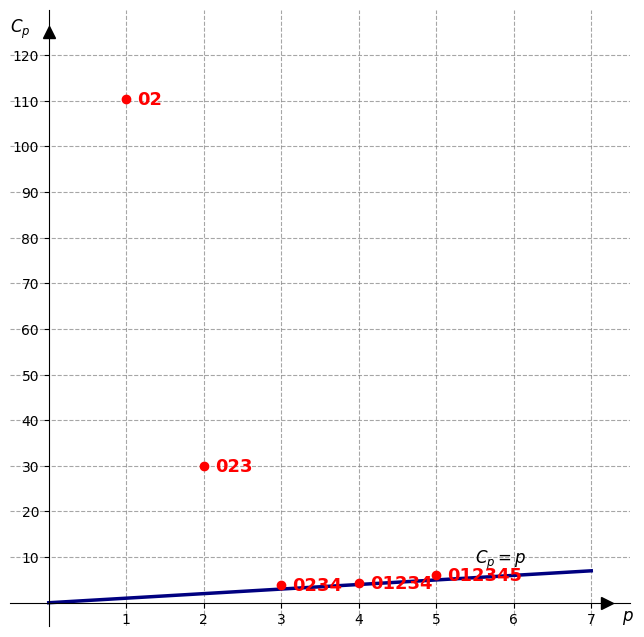

In [3]:
p_values = [1, 2, 3, 4, 5]
cp_values = [110.4898, 30.0195, 3.9477, 4.3861, 6.0]
labels = ['02', '023', '0234', '01234', '012345']

fig, ax = plt.subplots(figsize=(8, 8))

# 1. Побудова прямої Cp = p
# Пряму малюємо до 7 (за межами осі X вона не потрібна)
ax.plot([0, 7], [0, 7], color='navy', linewidth=2.5)
# Текст зміщено відповідно до нового масштабу
ax.text(5.5, 8.5, '$C_p = p$', fontsize=12, color='black')

# 2. Побудова точок значень Cp
ax.scatter(p_values, cp_values, color='red', zorder=5)

# 3. Додавання підписів до точок
for p, cp, label in zip(p_values, cp_values, labels):
    ax.annotate(label, (p, cp), 
                textcoords="offset points", 
                xytext=(8, -4), # Зміщення тексту вправо та вниз
                color='red', 
                fontsize=13, 
                fontweight='bold')

# Налаштування вигляду осей (перенесення в нуль)
ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

# Стрілки на кінцях осей (прив'язані до конкретних координат даних)
ax.plot(7.2, 0, ls="", marker=">", ms=8, color="k", clip_on=False)
ax.plot(0, 125, ls="", marker="^", ms=8, color="k", clip_on=False)

# Налаштування поділок та сітки (адаптовано під масштаб 120)
ax.set_xticks(range(1, 8))
ax.set_yticks(range(10, 121, 10)) # Поділки по осі Y кожні 10 одиниць
ax.grid(True, linestyle='--', color='gray', alpha=0.7, zorder=0)

# Підписи осей (зміщено під нові ліміти)
ax.text(7.4, -4, '$p$', fontsize=12, style='italic')
ax.text(-0.5, 125, '$C_p$', fontsize=12, style='italic')

# Обмеження осей (пропорційно розширені)
ax.set_xlim(-0.5, 7.5)
ax.set_ylim(-5, 130)

plt.show()

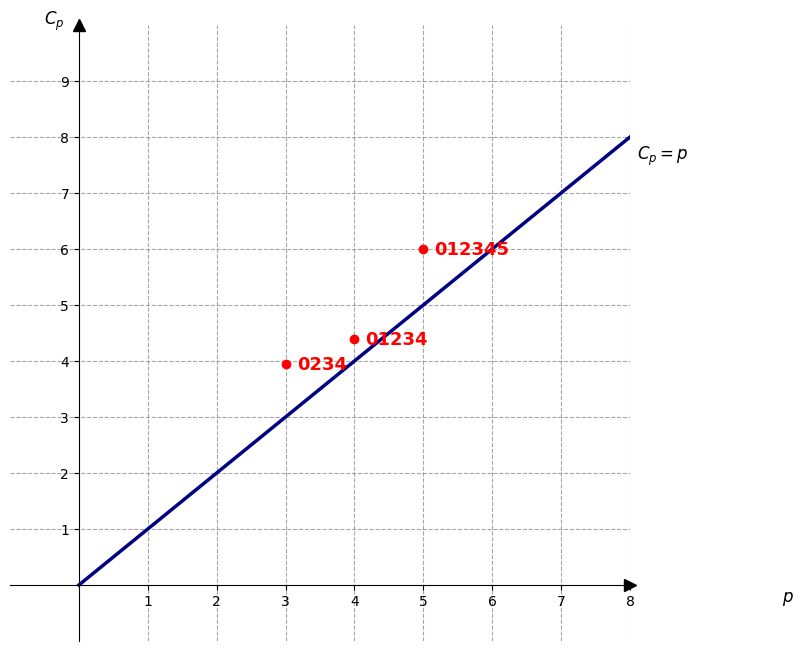

In [4]:
p_values = [1, 2, 3, 4, 5]
cp_values = [110.4898, 30.0195, 3.9477, 4.3861, 6.0]
labels = ['02', '023', '0234', '01234', '012345']

fig, ax = plt.subplots(figsize=(8, 8))

# 1. Побудова прямої Cp = p
# Беремо діапазон від 0 до 10 для осей
ax.plot([0, 120], [0, 120], color='navy', linewidth=2.5)
ax.text(8.1, 7.6, '$C_p = p$', fontsize=12, color='black')

# 2. Побудова точок значень Cp
ax.scatter(p_values, cp_values, color='red', zorder=5)

# 3. Додавання підписів до точок
for p, cp, label in zip(p_values, cp_values, labels):
    ax.annotate(label, (p, cp), 
                textcoords="offset points", 
                xytext=(8, -4), # Зміщення тексту вправо та трохи вниз
                color='red', 
                fontsize=13, 
                fontweight='bold')

# Налаштування вигляду осей (перенесення в нуль)
ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

# Додавання імітації стрілок на кінцях осей
ax.plot((1), (0), ls="", marker=">", ms=8, color="k",
        transform=ax.get_yaxis_transform(), clip_on=False)
ax.plot((0), (1), ls="", marker="^", ms=8, color="k",
        transform=ax.get_xaxis_transform(), clip_on=False)

# Налаштування поділок та сітки
ax.set_xticks(range(1, 10))
ax.set_yticks(range(1, 10))
ax.grid(True, linestyle='--', color='gray', alpha=0.7, zorder=0)

# Підписи осей
ax.text(10.2, -0.3, '$p$', fontsize=12, style='italic')
ax.text(-0.5, 10, '$C_p$', fontsize=12, style='italic')

# Обмеження осей
ax.set_xlim(-1, 8)
ax.set_ylim(-1, 10)

plt.show()

Так як регресор x1 мало впливовий, то за «найкращу модель» оберемо модель з х0 х2 х3 х4.

In [10]:
def format_equation(params, var_names):
    terms = []
    for i, (name, coef) in enumerate(zip(var_names, params)):
        v_name = f" x_{name[-1]}"
        
        if i == 0:
            terms.append(f"{coef:.4f}{v_name}")
        else:
            sign = "+" if coef >= 0 else "-"
            terms.append(f"{sign} {abs(coef):.4f}{v_name}")
    return " ".join(terms).strip()


y = df['Y1']
T = len(y)

# Словник з найкращими моделями для кожної групи
best_models = {
    'Б': ['X0', 'X2'],
    'В': ['X0', 'X2', 'X3'],
    'Г': ['X0', 'X2', 'X3', 'X4'],
    'Д': ['X0', 'X1', 'X2', 'X3', 'X4'],
    'Е': ['X0', 'X1', 'X2', 'X3', 'X4', 'X5']
}

min_af = float('inf')
best_group_name = None
best_equation = ""

print("Скористаємося критерієм Амемії для знаходження найкраще специфікованої моделі з найкращих моделей у групі.\n")

# Проходимо по всіх групах для оцінки
for i, (group, vars_list) in enumerate(best_models.items()):
    X = df[vars_list]
    
    # Будуємо модель
    model = sm.OLS(y, X).fit()
    rss = np.sum(model.resid ** 2) # Сума квадратів залишків
    N = len(vars_list) # Кількість параметрів (з урахуванням константи)
    
    # Розрахунок критерію Амемії
    af = (rss * (T + N)) / (T - N)
    
    eq_str = format_equation(model.params, vars_list)
    
    # Визначаємо найкращу модель (з найменшим AF)
    if af < min_af:
        min_af = af
        best_group_name = group
        best_equation = eq_str
        
    if i == 0:
        print(f"У групі {group} найкращою за трьома критеріями є модель y\u0302 = {eq_str}. Значення вирішальної функції дорівнює AF = {af:.4f}.")
    elif i == 1:
        print(f"У групі {group}: y\u0302 = {eq_str}, AF = {af:.4f}.")
    elif i == len(best_models) - 1:
        print(f"І нарешті у групі {group}:\n")
        print(f"      y\u0302 = {eq_str},  AF = {af:.4f}.\n")
    else:
        print(f"Далі, у групі {group}:\n")
        print(f"      y\u0302 = {eq_str},  AF = {af:.4f}.\n")

print(f"Так як у моделі з групи {best_group_name} AF найменше, то модель y\u0302 = {best_equation} краще всіх специфікована.")

Скористаємося критерієм Амемії для знаходження найкраще специфікованої моделі з найкращих моделей у групі.

У групі Б найкращою за трьома критеріями є модель ŷ = 81.4983 x_0 - 0.6573 x_2. Значення вирішальної функції дорівнює AF = 1220.4403.
У групі В: ŷ = 89.1911 x_0 - 0.5760 x_2 - 1.0609 x_3, AF = 608.3915.
Далі, у групі Г:

      ŷ = 82.8956 x_0 - 0.3777 x_2 - 1.1723 x_3 + 0.0004 x_4,  AF = 398.8463.

Далі, у групі Д:

      ŷ = 83.4380 x_0 - 0.0000 x_1 - 0.3860 x_2 - 1.1733 x_3 + 0.0003 x_4,  AF = 401.1031.

І нарешті у групі Е:

      ŷ = 82.1702 x_0 - 0.0000 x_1 - 0.3748 x_2 - 1.1501 x_3 + 0.0003 x_4 + 0.0151 x_5,  AF = 413.5418.

Так як у моделі з групи Г AF найменше, то модель ŷ = 82.8956 x_0 - 0.3777 x_2 - 1.1723 x_3 + 0.0004 x_4 краще всіх специфікована.


In [13]:
def format_equation(params, var_names):
    terms = []
    for i, (name, coef) in enumerate(zip(var_names, params)):
        if i == 0:
            terms.append(f"{coef:.4f} {name}")
        else:
            sign = "+" if coef >= 0 else "-"
            terms.append(f"{sign} {abs(coef):.4f} {name}")
    return " ".join(terms)


X = df[['X0', 'X2', 'X3', 'X4']] 
y = df['Y1']

T = len(y)
alpha = 0.05

# 1. Оцінка базової моделі
model_1 = sm.OLS(y, X).fit()
y_hat = model_1.predict(X)
rss_1 = np.sum(model_1.resid ** 2)

var_names_1 = ['x_0', 'x_2', 'x_3', 'x_4']
eq_1 = format_equation(model_1.params, var_names_1)

# 2. Оцінка розширеної моделі
X_ext = X.copy()
X_ext['y_hat_2'] = y_hat ** 2
X_ext['y_hat_3'] = y_hat ** 3
X_ext['y_hat_4'] = y_hat ** 4

model_2 = sm.OLS(y, X_ext).fit()
rss_2 = np.sum(model_2.resid ** 2)

var_names_2 = ['x_0', 'x_2', 'x_3', 'x_4', 'y\u0302\u00B2', 'y\u0302\u00B3', 'y\u0302\u2074']
eq_2 = format_equation(model_2.params, var_names_2)

# 3. Розрахунок F-статистики
f_ct = ((rss_1 - rss_2) * (T - 3)) / (3 * rss_2)
df2 = T - 3
f_kp = stats.f.ppf(1 - alpha, 3, df2)


print("Для з'ясування питання про специфікацію моделі скористаємося критерієм Рамсея.\n")
print(f"Для моделі y\u0302 = {eq_1} розрахуємо y\u0302_t і u_1t (t = 1,{T}). Далі отримаємо, що RSS_1 = \u2211 u_1t\u00B2 = {rss_1:.4f}.\n")

print("Будуємо модель")
print("      y\u00B9 = \u03B2\u2081 x\u2081 + \u03B2\u2082 x\u2082 + \u03B2\u2083 x\u2083 + \u03B2\u2084 x\u2084 + \u03B2\u2085 y\u0302\u00B2 + \u03B2\u2086 y\u0302\u00B3 + \u03B2\u2087 y\u0302\u2074 + u\u2082,\n")
print("вона має вигляд\n")
print(f"y\u0302\u00B9 = {eq_2}.\n")

print(f"Розраховуємо y\u0302\u00B9_t, u_2t і RSS_2 = \u2211 u_2t\u00B2. Отримуємо: RSS_2 = {rss_2:.4f}. Тепер можна розрахувати F_CT:\n")
print(f"      F_CT = ((RSS_1 - RSS_2)(T - 3)) / (3 * RSS_2) = {f_ct:.4f}.\n")

sign = "<" if f_ct < f_kp else ">"
conclusion = "добре специфікована" if f_ct < f_kp else "погано специфікована"

print(f"F_KP = F(\u03B1; 3; T - 3) = F({alpha}; 3; {df2}) = {f_kp:.2f}. Так як F_CT {sign} F_KP, то обрана нами модель {conclusion}.")

Для з'ясування питання про специфікацію моделі скористаємося критерієм Рамсея.

Для моделі ŷ = 82.8956 x_0 - 0.3777 x_2 - 1.1723 x_3 + 0.0004 x_4 розрахуємо ŷ_t і u_1t (t = 1,52). Далі отримаємо, що RSS_1 = ∑ u_1t² = 341.8682.

Будуємо модель
      y¹ = β₁ x₁ + β₂ x₂ + β₃ x₃ + β₄ x₄ + β₅ ŷ² + β₆ ŷ³ + β₇ ŷ⁴ + u₂,

вона має вигляд

ŷ¹ = 852.6034 x_0 - 4.1353 x_2 - 13.0419 x_3 + 0.0041 x_4 - 0.4033 ŷ² + 0.0061 ŷ³ - 0.0000 ŷ⁴.

Розраховуємо ŷ¹_t, u_2t і RSS_2 = ∑ u_2t². Отримуємо: RSS_2 = 290.8100. Тепер можна розрахувати F_CT:

      F_CT = ((RSS_1 - RSS_2)(T - 3)) / (3 * RSS_2) = 2.8677.

F_KP = F(α; 3; T - 3) = F(0.05; 3; 49) = 2.79. Так як F_CT > F_KP, то обрана нами модель погано специфікована.
